# Etapa 2 — Limpeza e análise exploratória da dengue no Nordeste

Período dos sintomas: 2000–2025. Fontes: SINAN/MS e IBGE.

A definição principal é operacional e inclui inconclusivos; o cenário estrito demonstra sensibilidade à classificação. Leia `docs/metodologia_etapa2.md`. O notebook usa os produtos disponíveis; ative `REPROCESSAR` para reconstruí-los pelos scripts.


In [1]:
from pathlib import Path
import sys, json, os
import pandas as pd
from IPython.display import display, Image, Markdown
base=Path.cwd().resolve()
candidatos=[base,base/"dengue_nordeste",*base.parents]
ROOT=next(p for p in candidatos if (p/"scripts/limpar_analisar.py").exists())
sys.path.insert(0,str(ROOT/"scripts"))
os.environ.setdefault("MPLCONFIGDIR",str(ROOT/"tmp/matplotlib"))
REPROCESSAR=False
print("Projeto:",ROOT)


Projeto: C:\Users\rayan\OneDrive\Documentos\ChatGPT\Ciências de Dados\dengue_nordeste


## 1. Preparação e execução

A primeira execução sem produtos faz a coleta/integração necessárias. Os arquivos originais e recortes individuais não são versionados. A reconstrução pode levar vários minutos e exige internet.


In [2]:
from executar_etapa2 import executar_etapa
executar_etapa(reprocessar=REPROCESSAR,documentar=False)
DATA=ROOT/"data/processed/etapa2"
meta=json.loads((ROOT/"data/metadata/validacao_etapa2.json").read_text(encoding="utf-8"))
print("Entrada:",meta["registros_entrada"])
print("Prováveis operacionais:",meta["casos_probaveis_operacionais"])
print("Cenário estrito:",meta["casos_criterio_estrito"])
print("Data-limite das notificações:",meta["data_corte_notificacoes"])


Usando tabelas da Etapa 2 já produzidas. --reprocessar refaz a limpeza.
Entrada: 5475862
Prováveis operacionais: 4174601
Cenário estrito: 2807094
Data-limite das notificações: 2026-10-29


## 2. Auditoria dos filtros

Os motivos de exclusão são exclusivos; flags podem se sobrepor. Não há exclusão automática de outliers, remoção de linhas idênticas ou imputação de sintomas/população.


In [3]:
aud=pd.read_csv(DATA/"auditoria_limpeza.csv")
cols=["ano_arquivo","registros","incluidos","criterio_estrito","nu_ano_divergente_data","incluidos_atraso_superior60"]
display(aud[cols])
display(pd.DataFrame(list(meta["exclusoes"].items()),columns=["Motivo exclusivo","Registros"]))


,ano_arquivo,registros,incluidos,criterio_estrito,nu_ano_divergente_data,incluidos_atraso_superior60
0,2000,83260,70120,49449,1,685
1,2001,180993,149768,92693,40,1609
2,2002,326145,267680,179210,28,2725
3,2003,207684,151330,107528,1,1229
4,2004,41865,22347,16701,0,201
5,2005,124677,75938,60351,0,800
6,2006,107714,69704,57995,0,663
7,2007,175518,125586,91090,0,1030
8,2008,299720,208960,147412,2,1693
9,2009,177798,126524,83027,0,639


,Motivo exclusivo,Registros
0,uf_invalida,0
1,notificacao_invalida_ou_fora_recorte,1
2,agravo_incompativel_ou_ausente,13
3,duplicidade_marcada,6
4,classificacao_desconhecida,0
5,descartado,1296090
6,chikungunya,0
7,sintomas_invalidos_ou_fora_recorte,5137
8,sintomas_apos_notificacao,14


## 3. Verificações das bases

Chaves, reconciliação estadual/municipal/mensal, taxas, sazonalidade, ausência de 2023 e hashes são conferidos pelo validador independente. No pacote portátil sem originais, a conferência de hashes exige reconstruir os recortes; as verificações das tabelas continuam disponíveis nas células abaixo.


In [4]:
tipos={"codigo_uf":"string","codigo_municipio_6":"string","codigo_ibge":"string"}
estados=pd.read_csv(DATA/"estado_ano_limpo.csv",dtype=tipos)
municipios=pd.read_csv(DATA/"municipio_ano_limpo.csv",dtype=tipos)
mensal=pd.read_csv(DATA/"estado_mes_sintomas.csv",dtype=tipos)
nordeste=pd.read_csv(DATA/"nordeste_ano.csv")
assert len(estados)==234
assert not estados.duplicated(["codigo_uf","ano"]).any()
assert not municipios.duplicated(["codigo_municipio_6","ano"]).any()
assert int(estados.casos_probaveis_operacionais.sum())==int(mensal.casos_probaveis_operacionais.sum())==meta["casos_probaveis_operacionais"]
assert int(municipios.casos_probaveis_operacionais.sum())+meta["casos_sem_municipio_valido"]==meta["casos_probaveis_operacionais"]
assert estados.loc[estados.ano.eq(2023),"incidencia_100mil"].isna().all()
print("Verificações das tabelas concluídas.")


Verificações das tabelas concluídas.


## 4. Estatísticas descritivas e cobertura

A estatística municipal se restringe ao subconjunto com registros e população. As populações combinam censos e estimativas; a taxa de 2023 permanece ausente.


In [5]:
display(estados.groupby("uf")[["casos_probaveis_operacionais","incidencia_100mil"]].describe())
display(pd.read_csv(DATA/"cobertura_municipal.csv"))


casos_probaveis_operacionais                                                \
                          count          mean           std     min       25%   
uf                                                                              
AL                         26.0  11918.153846  11509.692732   945.0   3388.25   
BA                         26.0  46307.769231  45956.100368  4715.0  13779.00   
CE                         26.0  28638.846154  18274.123587  1427.0  14927.50   
MA                         26.0   6454.076923   4675.364978  1369.0   3638.75   
PB                         26.0  11441.076923   8494.457308    49.0   6153.50   
PE                         26.0  25647.038462  26534.152308  2344.0   8242.00   
PI                         26.0   7716.576923   5944.792586   879.0   4605.25   
RN                         26.0  18654.538462  13720.042517  2691.0   7762.50   
SE                         26.0   3783.500000   5685.557361   234.0    806.75   

                                incidencia_100mil                          \
        50%       75%       max             count        mean         std   
uf                                                                          
AL   7862.5  16878.25   47446.0              25.0  382.987599  366.844731   
BA  38701.0  58654.75  232511.0              25.0  318.724145  316.502086   
CE  27862.5  38227.75   63112.0              25.0  341.188666  213.441998   
MA   5728.5   7187.75   23718.0              25.0   99.654394   70.422870   
PB   9799.5  14889.50   35735.0              25.0  300.889421  218.711721   
PE  19801.5  30336.00  107692.0              25.0  295.394822  305.506105   
PI   6944.0   9464.75   31606.0              25.0  245.428315  186.353503   
RN  17085.0  23618.00   56769.0              25.0  594.128951  424.720647   
SE   1881.5   4730.50   29649.0              25.0  187.111681  290.857858   

                                                                
          min         25%         50%         75%          max  
uf                                                              
AL  33.479521  104.108892  259.356164  541.774351  1520.464388  
BA  34.461150   81.942986  261.140048  409.076307  1565.676553  
CE  19.204213  178.360281  345.374922  452.487009   739.283167  
MA  19.138122   53.397693   90.679716  108.432663   341.068122  
PB   1.422837  164.559153  271.838130  396.536372   893.505675  
PE  28.159840  103.568284  221.085255  360.126516  1235.907428  
PI  29.549218  150.853791  221.814541  318.821166   966.190073  
RN  85.767804  252.270577  569.242246  765.497844  1633.641228  
SE  10.270780   36.572114   83.759734  235.565184  1482.914152

,ano,municipios_na_base,municipios_com_registro,municipios_com_incidencia
0,2000,1799,1076,1071
1,2001,1802,1520,1512
2,2002,1803,1666,1657
3,2003,1797,1628,1625
4,2004,1798,1276,1272
5,2005,1799,1482,1477
6,2006,1794,1478,1478
7,2007,1793,1607,1607
8,2008,1797,1649,1646
9,2009,1796,1493,1491


## 5. Evolução, incidência e comparação estadual

Séries por início dos sintomas. O cenário estrito exige classificação de dengue e critério 1/2. A ausência de descartados em certos arquivos pode afetar a comparabilidade.


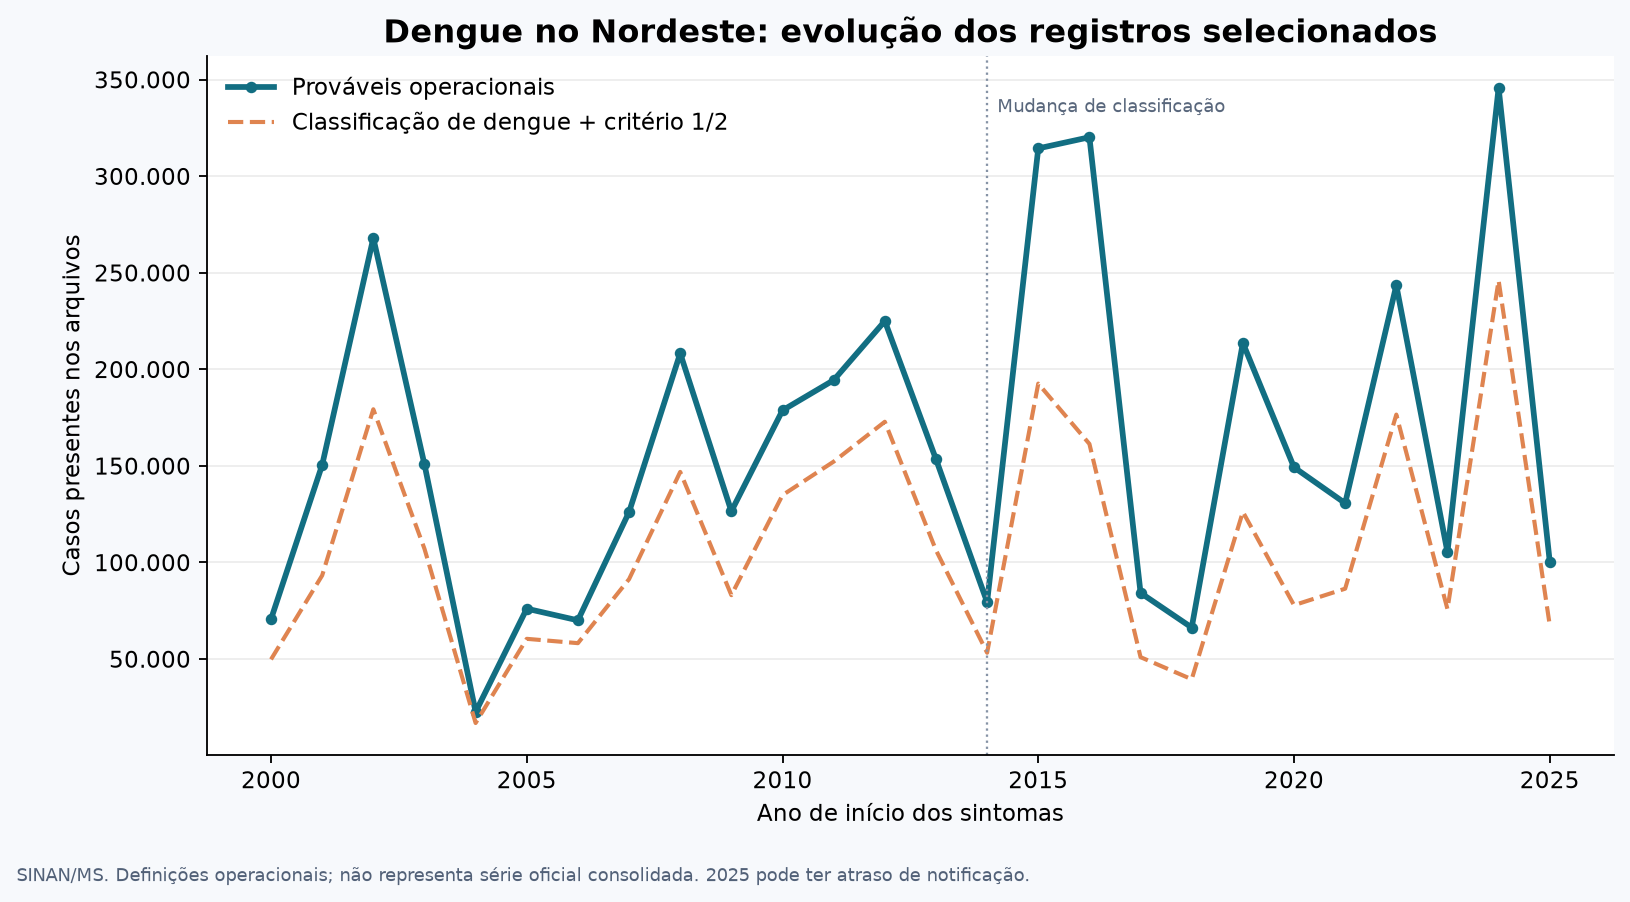

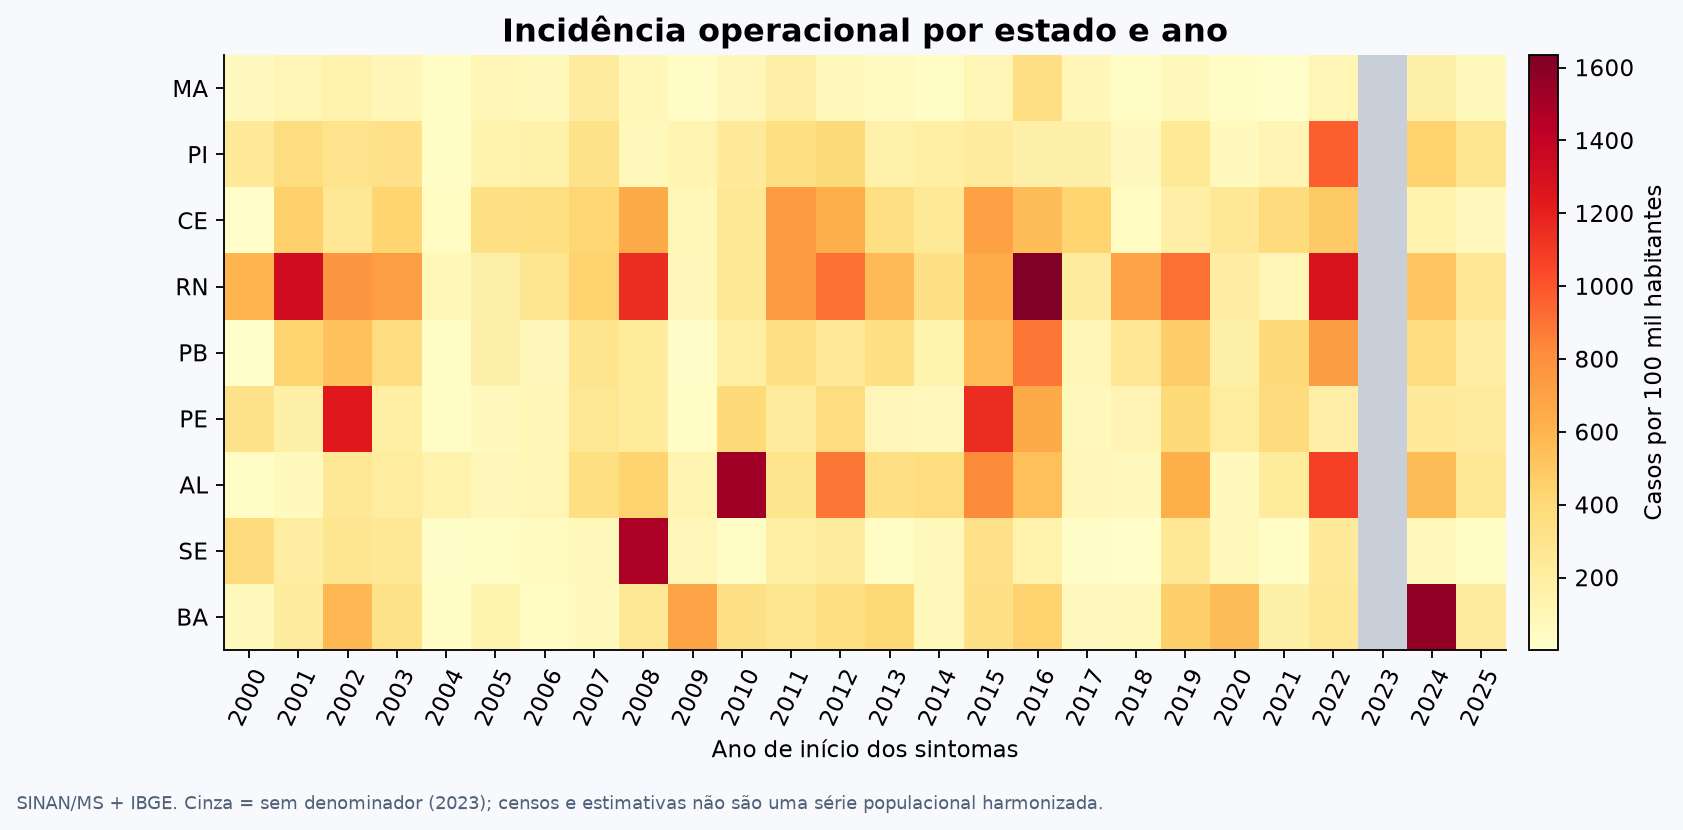

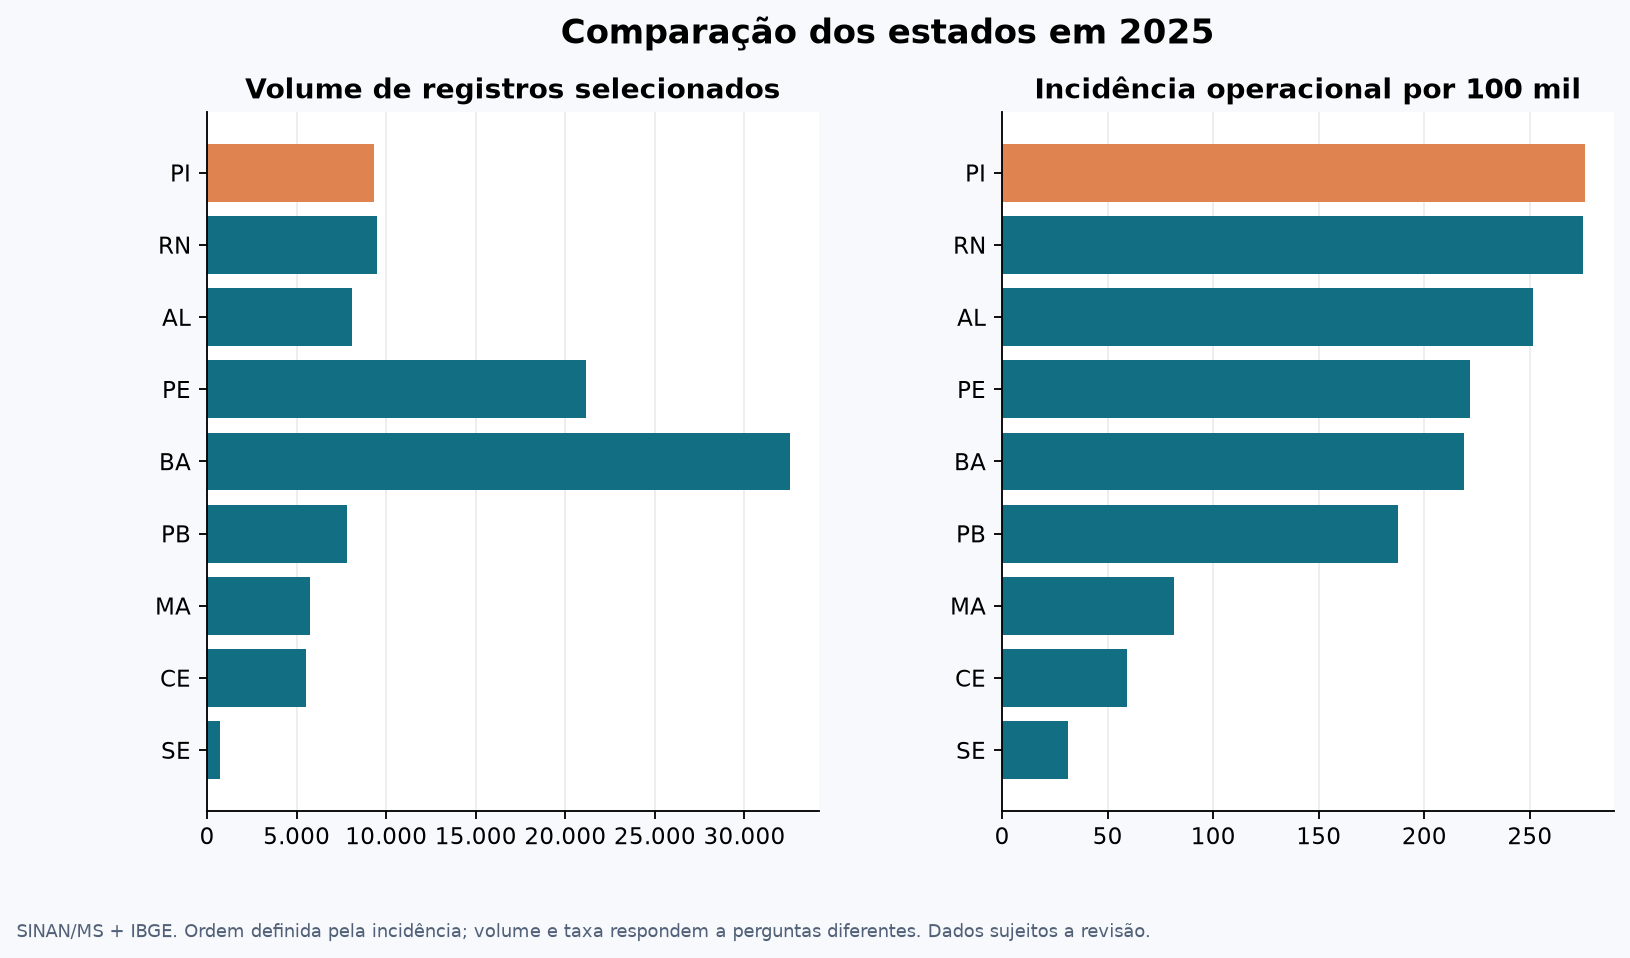

,uf,casos_probaveis_operacionais,casos_criterio_estrito,incidencia_100mil
51,PI,9338,7224,275.901029
103,RN,9513,4009,275.321281
181,AL,8106,7475,251.672851
155,PE,21178,15024,221.480700
233,BA,32514,16852,218.641674
129,PB,7807,7401,187.466923
25,MA,5719,3893,81.488003
77,CE,5495,4887,59.284683
207,SE,719,681,31.268687


In [6]:
for nome in ["01_evolucao_temporal.png","02_incidencia_estado_ano.png","03_comparacao_estados_2025.png"]:
    display(Image(filename=str(ROOT/"outputs/etapa2"/nome)))
display(estados.loc[estados.ano.eq(2025),["uf","casos_probaveis_operacionais","casos_criterio_estrito","incidencia_100mil"]].sort_values("incidencia_100mil",ascending=False))


## 6. Sazonalidade

Cada ano tem peso igual na média de participações mensais. A síntese usa 2001–2024 para reduzir efeitos de borda; não é teste de significância nem evidência causal climática.


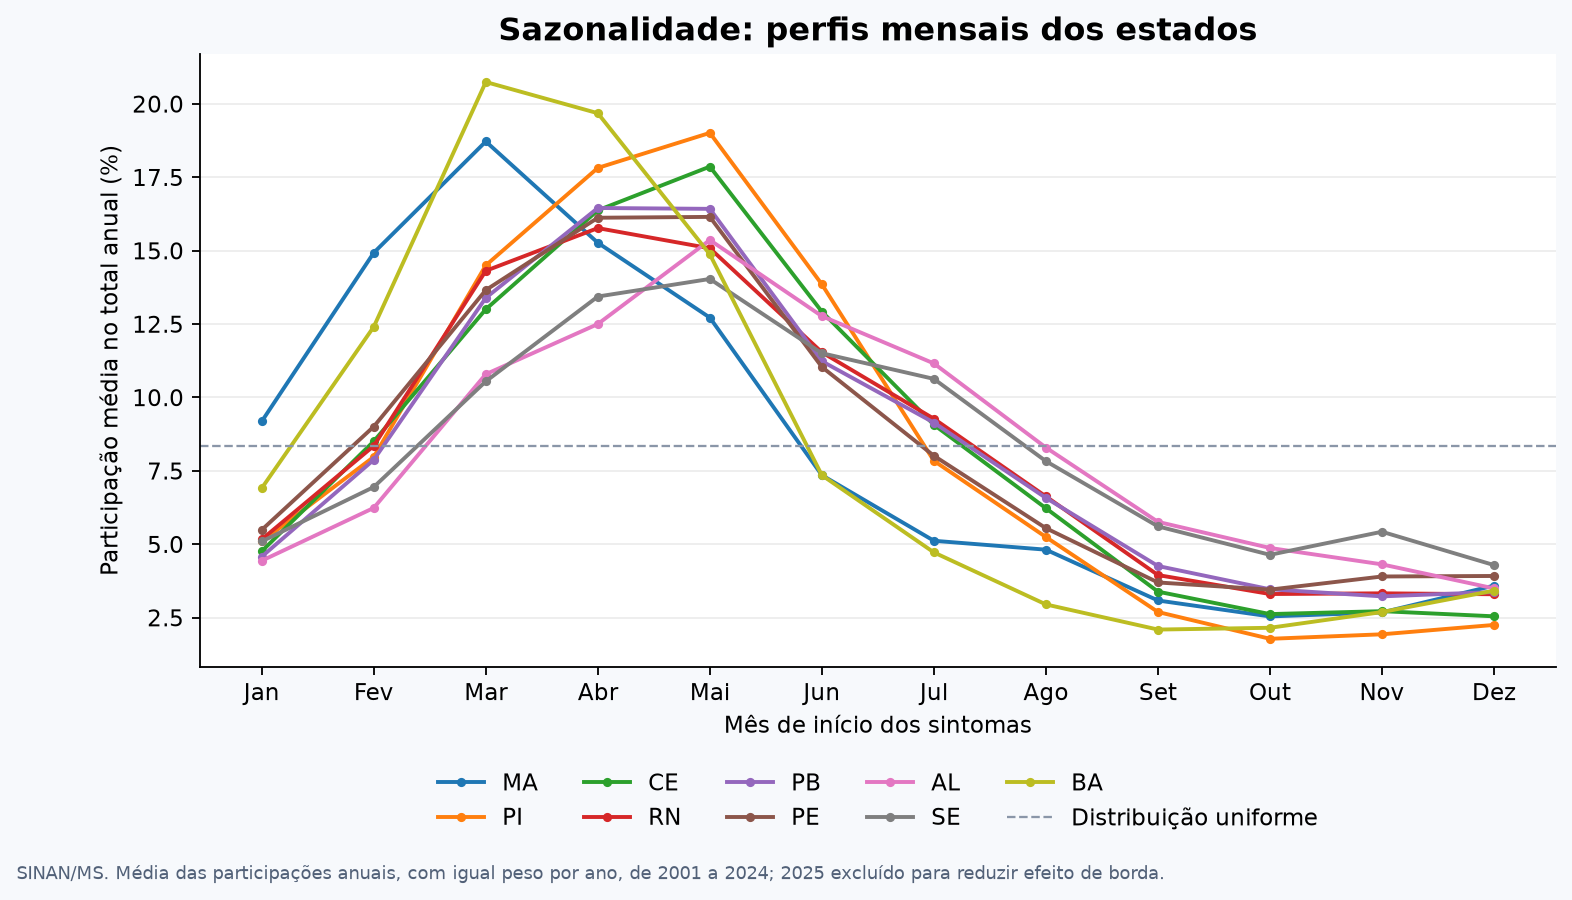

,mes,participacao_media_pct
0,1,5.392415
1,2,9.788301
2,3,15.831976
3,4,17.406315
4,5,16.497723
5,6,10.915914
6,7,7.772429
7,8,5.191366
8,9,3.139586
9,10,2.583584


In [7]:
display(Image(filename=str(ROOT/"outputs/etapa2/04_sazonalidade.png")))
display(pd.read_csv(DATA/"sazonalidade_nordeste.csv"))


## 7. Distribuição municipal, correlação e extremos

O ranking de 2024 usa população ≥ 10 mil e pelo menos 20 casos. Outliers permanecem nas bases; Tukey sinaliza extremos, sem distinguir sozinho erro de surto. A correlação refere-se a população versus contagem, não população versus incidência.


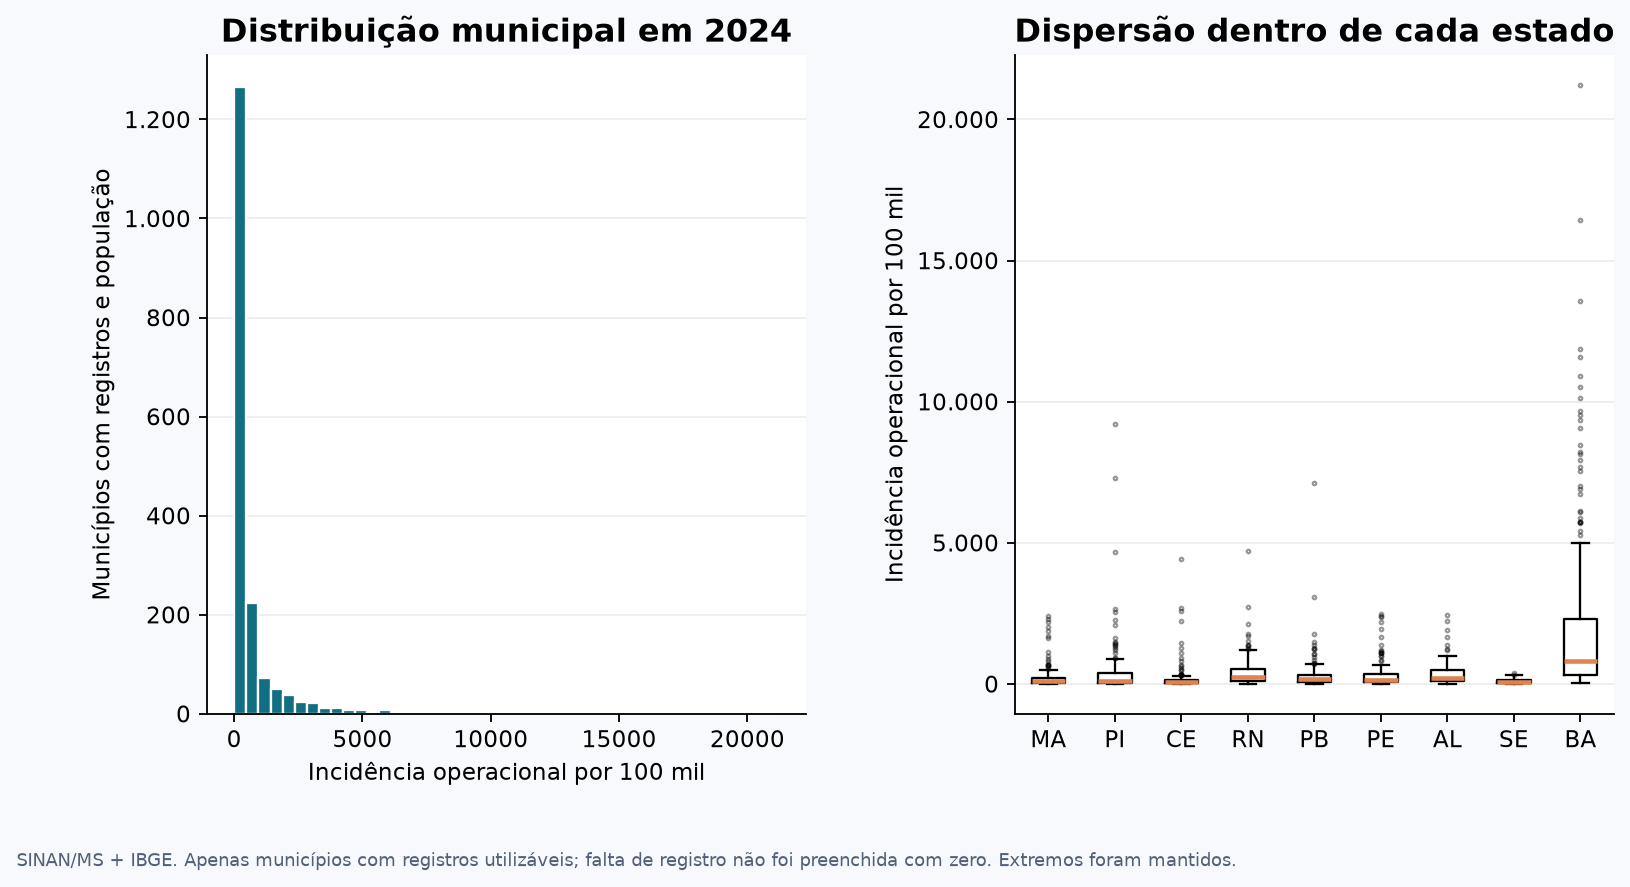

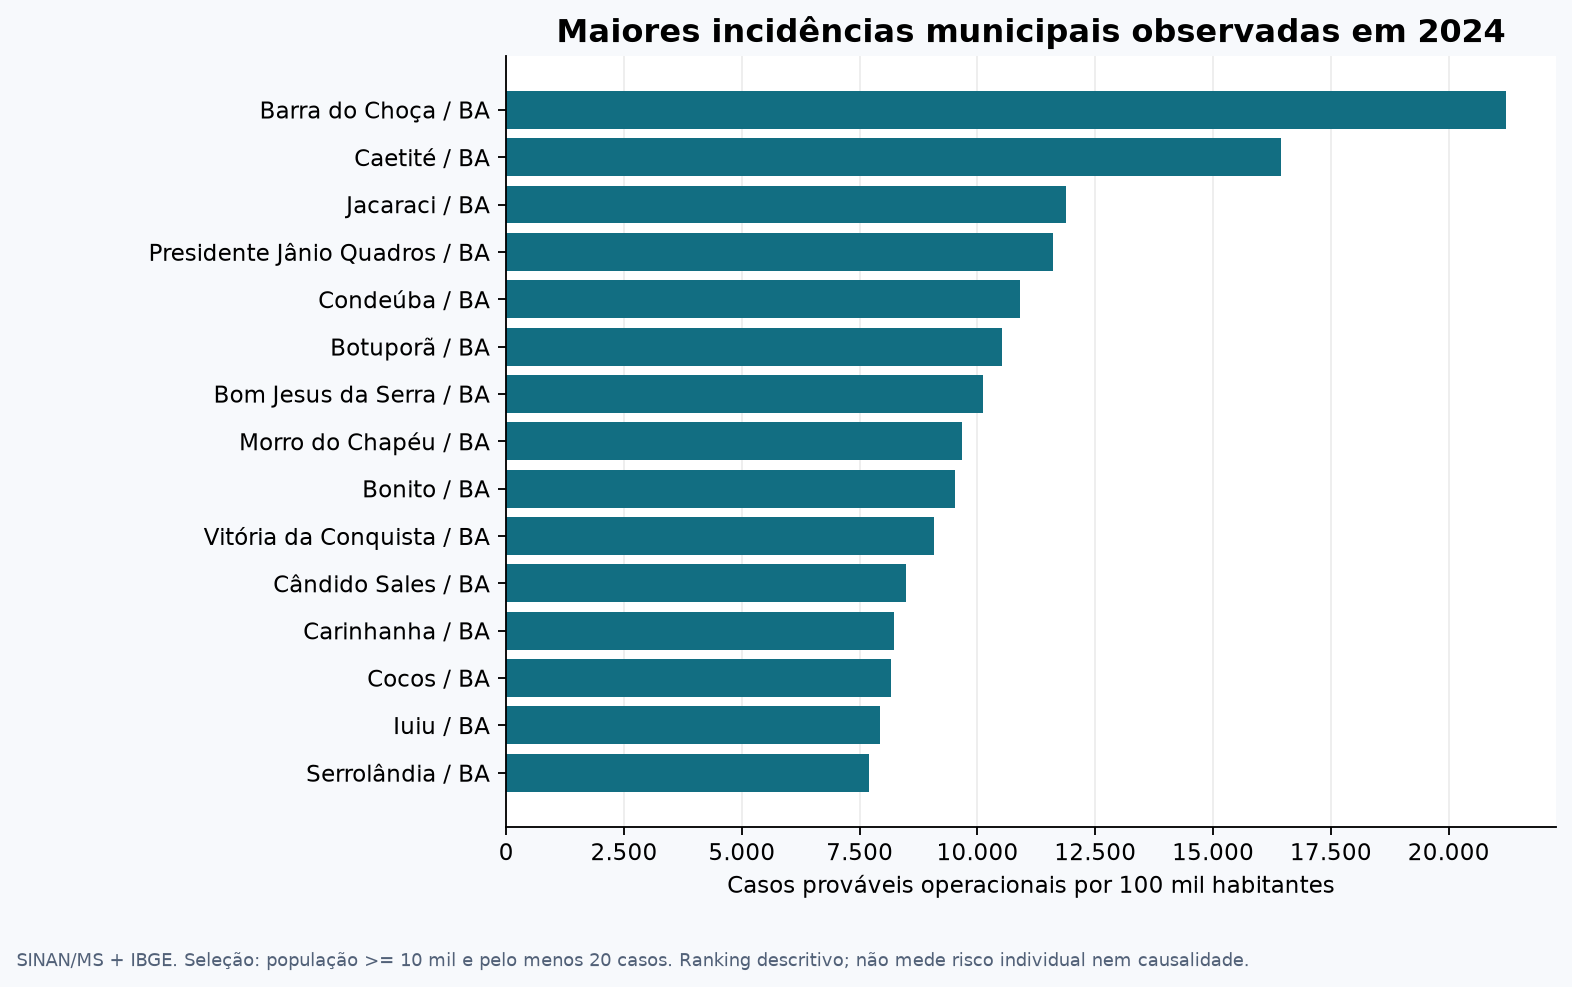

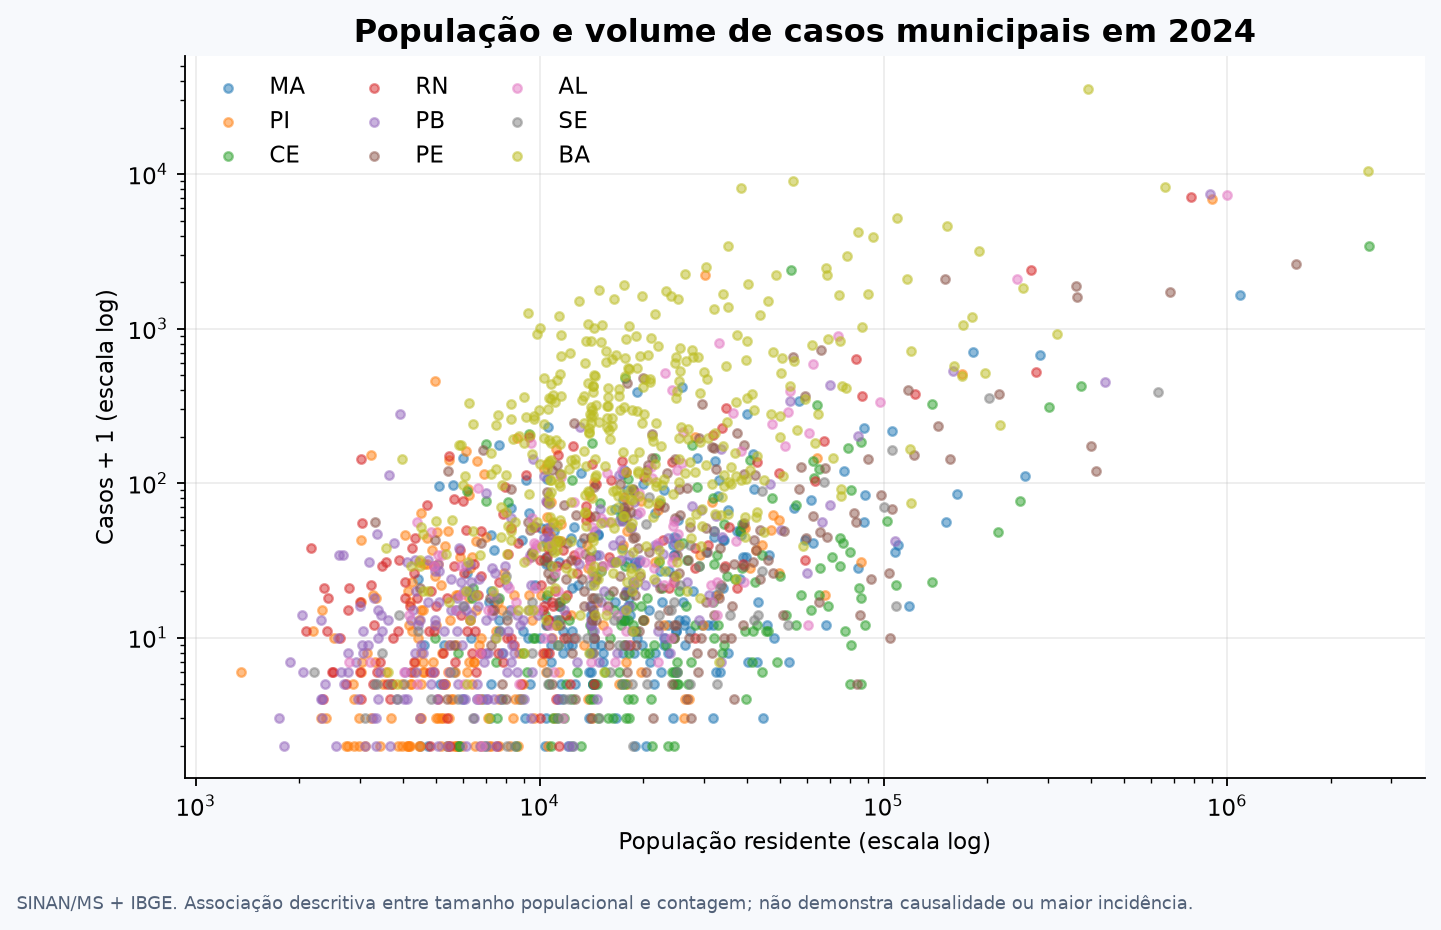

Spearman população × contagem em 2024: 0.4447398891654257


,uf,ano,incidencia_100mil,limite_superior_iqr_uf
0,MA,2007,218.810442,190.985118
1,MA,2016,341.068122,190.985118
2,PI,2022,966.190073,570.772230
3,RN,2016,1633.641228,1535.338743
4,PB,2016,893.505675,744.502202
5,PE,2002,1235.907428,744.963865
6,PE,2015,1152.381021,744.963865
7,AL,2010,1520.464388,1198.272540
8,SE,2008,1482.914152,534.054791
9,BA,2024,1565.676553,899.776288


In [8]:
for nome in ["05_distribuicoes_municipais.png","06_ranking_municipal.png","07_populacao_casos.png"]:
    display(Image(filename=str(ROOT/"outputs/etapa2"/nome)))
print("Spearman população × contagem em 2024:",meta["spearman_populacao_casos_municipais_2024"])
display(pd.read_csv(DATA/"outliers_estaduais.csv")[["uf","ano","incidencia_100mil","limite_superior_iqr_uf"]])


## 8. Distribuição espacial e qualidade

Os mapas têm escala comum. As malhas são estaduais, simplificadas e atuais; não harmonizam limites municipais históricos. Zero descartados no arquivo não comprova que não houve descartes na vigilância.


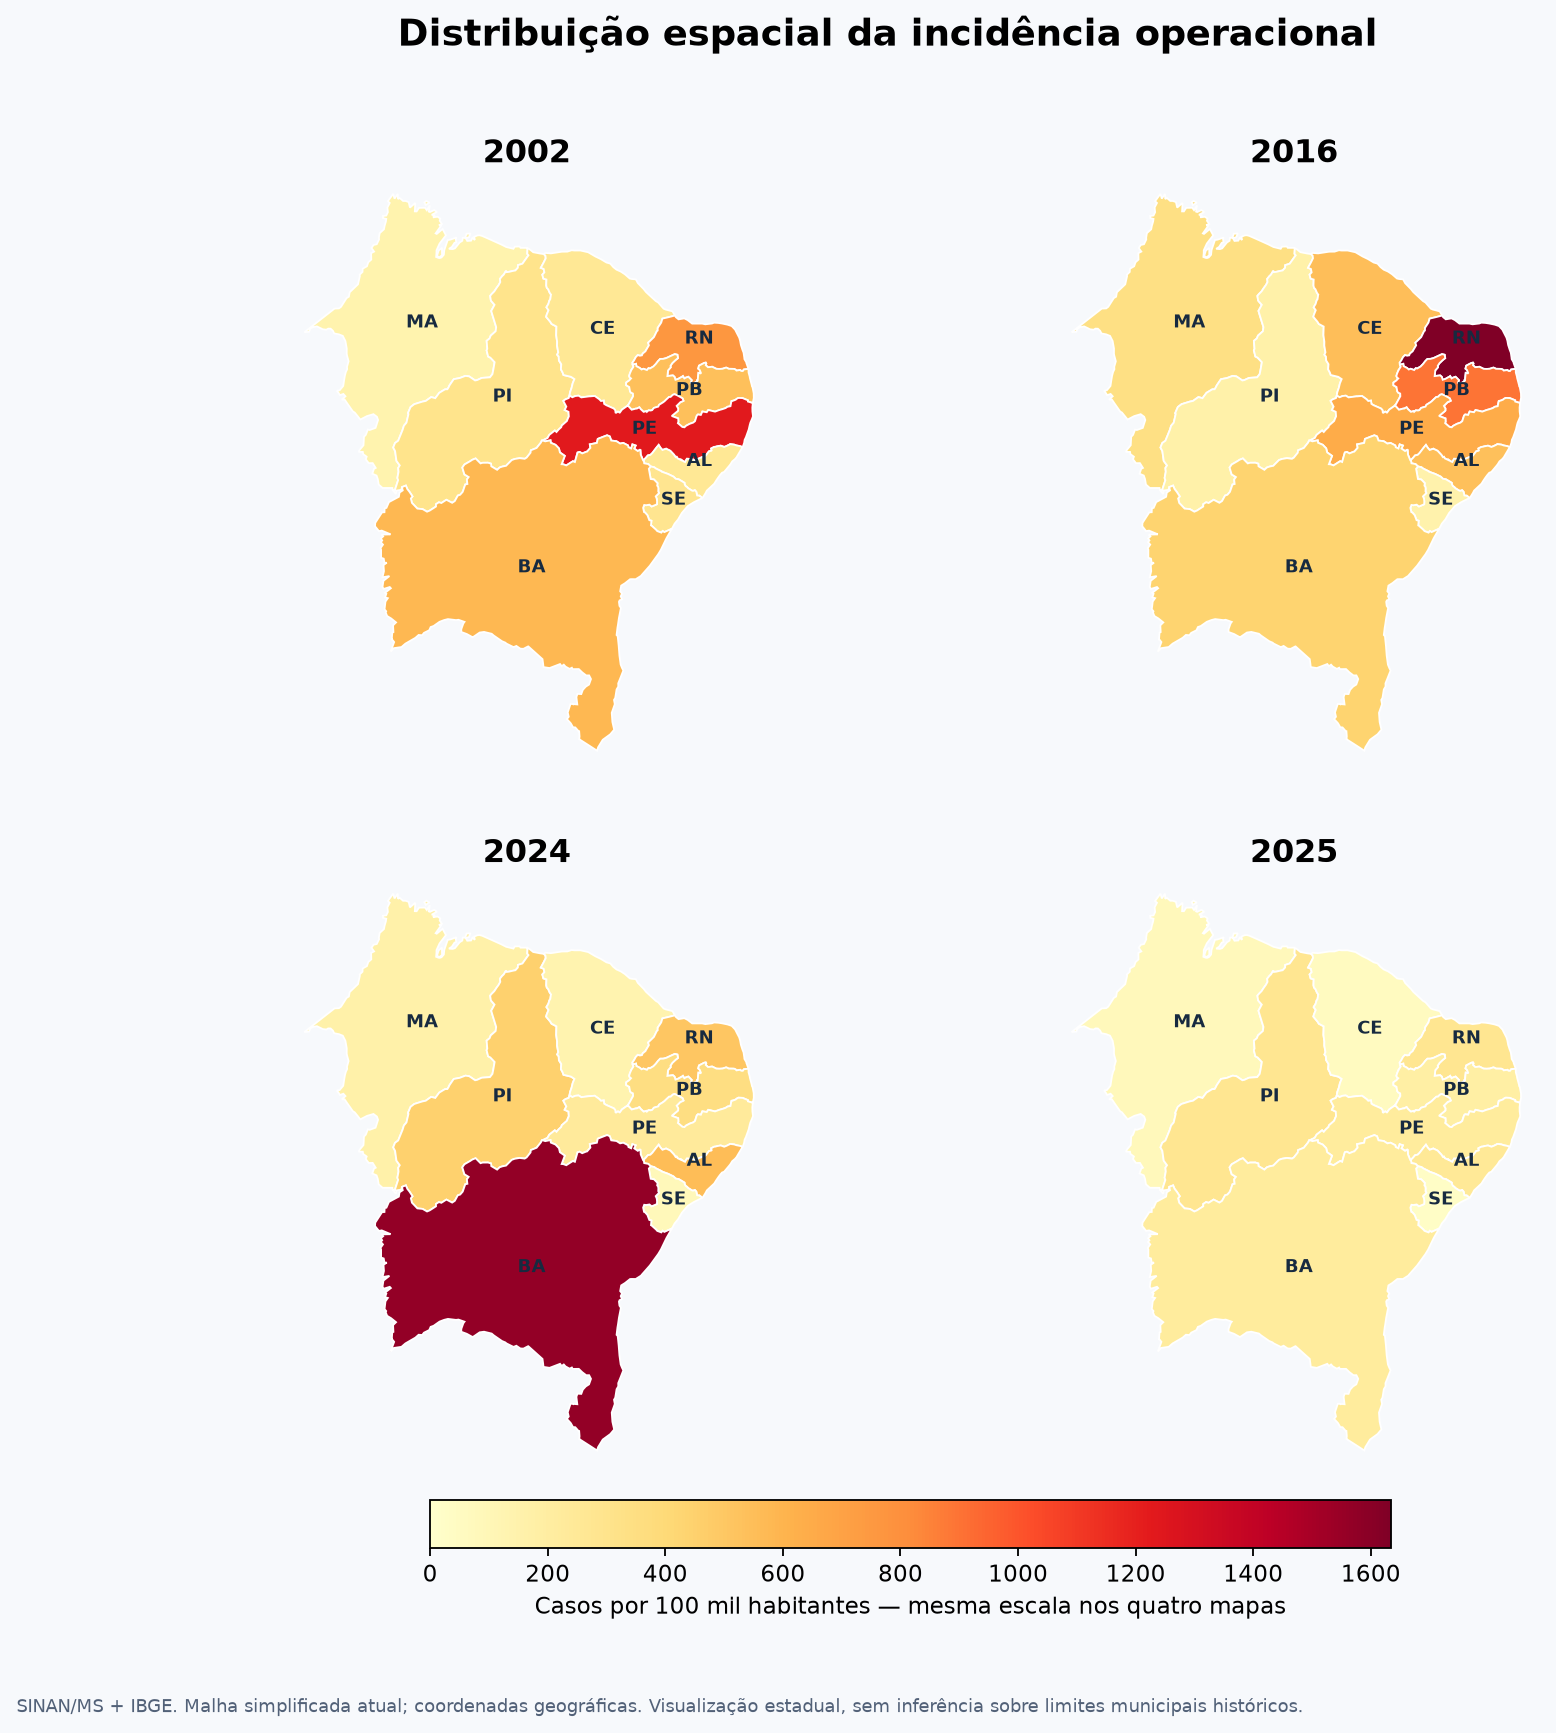

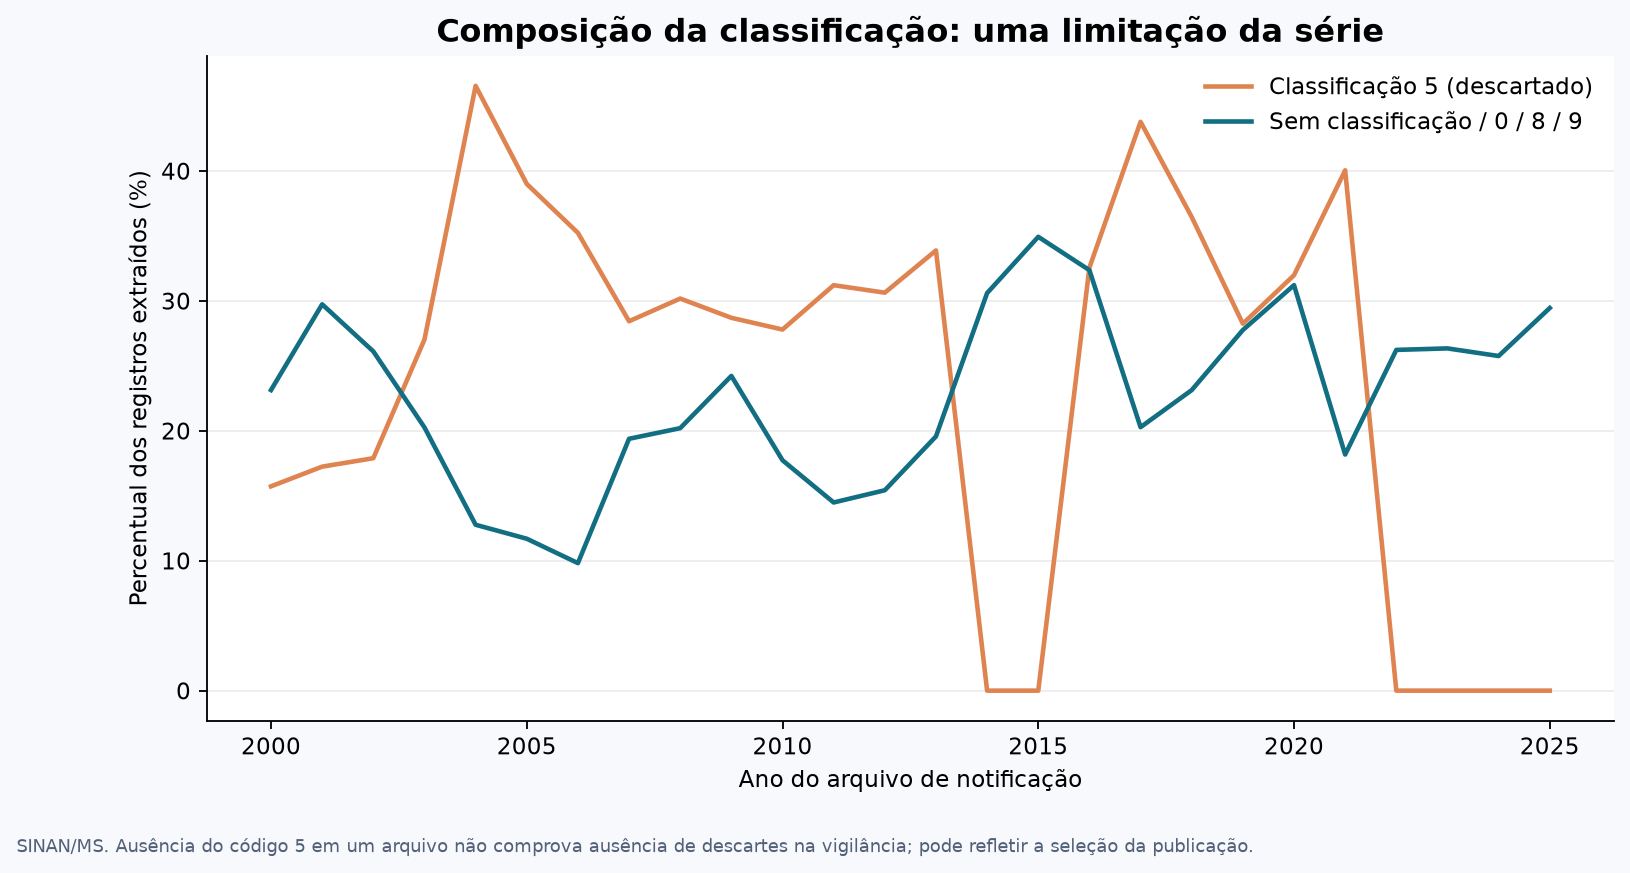

In [9]:
display(Image(filename=str(ROOT/"outputs/etapa2/08_mapas_estaduais.png")))
display(Image(filename=str(ROOT/"outputs/etapa2/09_qualidade_classificacao.png")))


## 9. Primeiras respostas e limitações

**Evolução temporal** — O maior volume no recorte selecionado aparece em 2024: 345.731 casos prováveis operacionais. No cenário estrito, o pico também deve ser verificado separadamente: 2024, com 246.034 registros. Esses picos descrevem os arquivos publicados e os filtros do projeto, sem demonstrar uma tendência causal ou uma série oficial consolidada.

**Diferenças entre estados** — Em 2025, PI apresenta a maior incidência operacional entre os nove estados: 275,9 por 100 mil habitantes. O gráfico de volumes e taxas mostra por que o maior número absoluto de casos não determina a maior incidência.

**Sazonalidade** — Na média das participações anuais de 2001 a 2024, 75,8% dos registros selecionados ocorrem de janeiro a junho. O mês de maior participação regional é 04. Os perfis estaduais diferem; esse padrão não foi submetido a teste de significância e não demonstra efeito causal de chuva ou temperatura.

**Valores atípicos** — Foram sinalizados 10 estados-ano acima do limite superior de Tukey no histórico da própria UF. Os outliers municipais comparam taxas dentro da mesma UF e ano. Todos foram mantidos; a classificação indica necessidade de investigação, não erro nem epidemia automaticamente.

**População e contagem** — Em municípios observados com população disponível em 2024, a correlação de Spearman entre população e volume de casos é 0,445. Ela descreve associação entre tamanho e contagem; não foi calculado teste inferencial e não se conclui que municípios maiores tenham maior incidência.

- A classificação 5 não aparece nos arquivos dos anos 2014, 2015, 2022, 2023, 2024, 2025. Não se interpreta essa ausência como inexistência de descartes na vigilância; a seleção da publicação pode afetar comparações temporais.
- A definição ampla inclui classificações inconclusivas, ignoradas ou ausentes. O cenário estrito permite avaliar parte dessa sensibilidade, sem ser padrão-ouro de diagnóstico.
- 2023 permanece sem denominador populacional e sem incidência. Não houve interpolação ou cópia automática de outro ano.
- As taxas municipais disponíveis descrevem municípios com registros utilizáveis e população. Municípios sem registro não foram transformados em zero; rankings e histogramas não representam todos os municípios.
- Censos, estimativas e alterações territoriais têm referências diferentes. As malhas estaduais dos mapas são simplificadas e atuais; não harmonizam retrospectivamente os municípios.
- Subnotificação, revisões, mudanças no sistema e duplicidades sem marcação identificável podem permanecer. Não foram ajustados modelos, testadas hipóteses ou estimadas relações causais.

Leia `docs/resultados_etapa2.md` e `docs/metodologia_etapa2.md` para métodos, fontes e declaração de uso de IA. As conclusões devem ser revisadas pelo grupo antes da entrega.
